In [1]:
import sys
import os
sys.path.append(os.path.abspath('../../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.ensembles import *
from functions.repeated_cv import *
from functions.postproc import *

from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import make_scorer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sksurv.metrics import integrated_brier_score
from sksurv.metrics import concordance_index_ipcw
from sksurv.nonparametric import kaplan_meier_estimator
from sklearn.inspection import permutation_importance

from sksurv.ensemble import RandomSurvivalForest
from sksurv.metrics import concordance_index_censored
from sksurv.util import Surv
from sksurv.ensemble import ComponentwiseGradientBoostingSurvivalAnalysis
from sksurv.linear_model import CoxnetSurvivalAnalysis

import time
set_config(display="text")  # displays text representation of estimators

In [2]:
dataset = pd.read_csv("data.csv")

diagnosis_variables = []

with open("diagnosis.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("treatment.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

survival_dataset = dataset.drop('Unnamed: 0', axis=1)

feature_columns = treatment_variables + diagnosis_variables

# continuous_features = feature_columns
continuous_features =  ['Age', 'Ki67 positive cells (%) at CB', 'Conventional RT fraction', 'Total administered dose', 'Boost dose administered']
continuous_features = [col for col in continuous_features if col in feature_columns]

In [16]:
# Cap survival days at 1825 and set event status to 0 for censored cases
survival_dataset.loc[survival_dataset['Survival days'] > 1826, 'Regional LN recurrence'] = 0
survival_dataset.loc[survival_dataset['Survival days'] > 1826, 'Survival days'] = 1826

# Prepare data
data_x = survival_dataset[feature_columns]
data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)
groups = survival_dataset['PERSON_ID']

# Stratification settings (toggle this flag)
n_splits = 5
use_time_strata = False  # Set to False to use outcome-only stratification
max_time_bins = 3

event_col = survival_dataset['Regional LN recurrence'].astype(int)
time_col = survival_dataset['Survival days']

strata_labels = None
chosen_bins = None
recurrence_mask = (event_col == 1)

if use_time_strata:
    # Outcome-Length stratification: time bins only for recurrence cases
    for n_bins in range(max_time_bins, 1, -1):
        try:
            # Build quantile bins using only recurrence cases
            recurrence_time_bins = pd.qcut(
                time_col.loc[recurrence_mask], q=n_bins, labels=False, duplicates='drop'
            )

            # Non-recurrence rows share one label; recurrence rows get time-bin labels
            candidate_labels = pd.Series('0_noevent', index=survival_dataset.index, dtype='object')
            candidate_labels.loc[recurrence_mask] = (
                '1_' + recurrence_time_bins.astype(int).astype(str)
            ).values

            # Every stratum must have at least n_splits samples for stable balancing
            if candidate_labels.value_counts().min() >= n_splits:
                strata_labels = candidate_labels
                chosen_bins = int(recurrence_time_bins.nunique())
                break
        except ValueError:
            continue

if strata_labels is None:
    # Explicit switch OR sparse recurrence-time bins -> outcome-only stratification
    strata_labels = event_col.astype(str)
    if use_time_strata:
        print('Fallback: using outcome-only stratification (recurrence time bins too sparse).')
    else:
        print('Using outcome-only stratification (time-based stratification disabled).')
else:
    print(f'Using recurrence-only time stratification with {chosen_bins} time bins.')

# sgkf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=12)
# cv = sgkf.split(X=data_x, y=strata_labels)

# train_index, test_index = next(cv)

manual_splits, manual_fold_summary = build_manual_stratified_group_folds(
    event_series=event_col,
    group_series=groups,
    strata_series=strata_labels,
    keep_groups_for_events=False,
    n_splits=n_splits,
    random_state=12
)

print('Manual grouped fold balancing summary:')
print(manual_fold_summary.to_string(index=False))

# Keep variable name for compatibility in later cells
cv = manual_splits
train_index, test_index = manual_splits[3]

x_train = data_x.iloc[train_index]
y_train = data_y[train_index]

x_test = data_x.iloc[test_index]
y_test = data_y[test_index]

subsampling = survival_dataset.iloc[train_index].copy()

print(f'Train size: {len(train_index)}, Test size: {len(test_index)}')

Using outcome-only stratification (time-based stratification disabled).
Manual grouped fold balancing summary:
 fold  target_events  assigned_events  target_samples  assigned_samples  valid_event_rate  target_event_strata_1  assigned_event_strata_1
    1              6                6             646               646          0.009288                      6                        6
    2              6                6             646               646          0.009288                      6                        6
    3              5                5             646               646          0.007740                      5                        5
    4              5                5             645               645          0.007752                      5                        5
    5              5                5             645               645          0.007752                      5                        5
Train size: 2583, Test size: 645


In [17]:
from sklearn.preprocessing import MinMaxScaler

# Define time points for calibration analysis (1, 2, 3, 4, 5 years)
time_points = [365, 730, 1095, 1460, 1825]  # in days

# Use the best model parameters found earlier
best_params_for_calibration = {
    'alphas': [0.000853168],
    'l1_ratio': 1.0,
    'fit_baseline_model': True
    }

n_controls=["Full"]

# predictions_df = pd.read_csv("cox_calibration_predictions.csv")

scaler = MinMaxScaler()
x_train_scaled = x_train.copy()

cols_to_scale = [col for col in continuous_features if col in x_train_scaled.columns]
x_train_scaled[cols_to_scale] = scaler.fit_transform(x_train_scaled[cols_to_scale])

x_test_scaled = x_test.copy()
x_test_scaled[cols_to_scale] = scaler.transform(x_test_scaled[cols_to_scale])

cox_model = CoxnetSurvivalAnalysis(**best_params_for_calibration)
cox_model.fit(x_train_scaled, y_train)

# Compute Harrell's c-index on train and test sets
train_risk = cox_model.predict(x_train_scaled)
c_index_train = concordance_index_censored(
    y_train["event"], y_train["time"], train_risk
)[0]

test_risk = cox_model.predict(x_test_scaled)
c_index_test = concordance_index_censored(
    y_test["event"], y_test["time"], test_risk
)[0]

print(f"Train c-index: {c_index_train:.4f}")
print(f"Test c-index: {c_index_test:.4f}")

# Build coefficient table
coef_array = cox_model.coef_
if coef_array.ndim == 1:
    coef_values = coef_array
else:
    # best_params_for_calibration has one alpha, so take first column
    coef_values = coef_array[:, 0]

coef_df = pd.DataFrame({
    "feature": x_train_scaled.columns,
    "coefficient": coef_values
})
coef_df["abs_coefficient"] = coef_df["coefficient"].abs()
coef_df = coef_df.sort_values("abs_coefficient", ascending=False).reset_index(drop=True)

# Optional: non-zero coefficients only
nonzero_coef_df = coef_df[coef_df["coefficient"] != 0].reset_index(drop=True)
size = len(nonzero_coef_df)

print("All coefficients (sorted by absolute value):")
print(coef_df.to_string(index=False))

print(f"\nNon-zero coefficients ({size}):")
print(nonzero_coef_df.to_string(index=False))

Train c-index: 0.9121
Test c-index: 0.9547
All coefficients (sorted by absolute value):
                                                  feature  coefficient  abs_coefficient
         Neoadjuvant (Only) therapy with biological drugs     1.719116         1.719116
                      Oestrogen receptor status at CB_1.0    -1.682097         1.682097
                              Radiotherapy (RT) performed    -0.838446         0.838446
                                        Isotype at CB_4.0     0.613977         0.613977
                                          Grade at CB_3.0     0.401600         0.401600
                     Radiotherapy on supraclavicular area     0.357675         0.357675
                              Side location of the lesion    -0.355422         0.355422
               Treatment in association with chemotherapy     0.344884         0.344884
Her2 overexpression (with immunohystochemistry) at CB_1.0     0.056411         0.056411
                  Adjuvant thera

## Grouping logs

In [60]:
# Event / non-event counts for each fold (train and validation)

event_series = survival_dataset['Regional LN recurrence'].astype(int).reset_index(drop=True)

if 'manual_splits' in globals():
    fold_iterator = manual_splits
else:
    fold_iterator = list(sgkf.split(X=data_x, y=strata_labels, groups=groups))

fold_rows = []
for fold_id, (tr_idx, va_idx) in enumerate(fold_iterator, start=1):
    tr_events = int(event_series.iloc[tr_idx].sum())
    tr_non_events = int(len(tr_idx) - tr_events)

    va_events = int(event_series.iloc[va_idx].sum())
    va_non_events = int(len(va_idx) - va_events)

    fold_rows.append({
        "fold": fold_id,
        "train_n": len(tr_idx),
        "train_events": tr_events,
        "train_non_events": tr_non_events,
        "train_event_rate": round(tr_events / len(tr_idx), 4) if len(tr_idx) > 0 else np.nan,
        "valid_n": len(va_idx),
        "valid_events": va_events,
        "valid_non_events": va_non_events,
        "valid_event_rate": round(va_events / len(va_idx), 4) if len(va_idx) > 0 else np.nan
    })

fold_event_counts_df = pd.DataFrame(fold_rows)
print(fold_event_counts_df.to_string(index=False))

 fold  train_n  train_events  train_non_events  train_event_rate  valid_n  valid_events  valid_non_events  valid_event_rate
    1     2581            21              2560            0.0081      646             6               640            0.0093
    2     2581            21              2560            0.0081      646             6               640            0.0093
    3     2582            22              2560            0.0085      645             5               640            0.0078
    4     2582            22              2560            0.0085      645             5               640            0.0078
    5     2582            22              2560            0.0085      645             5               640            0.0078


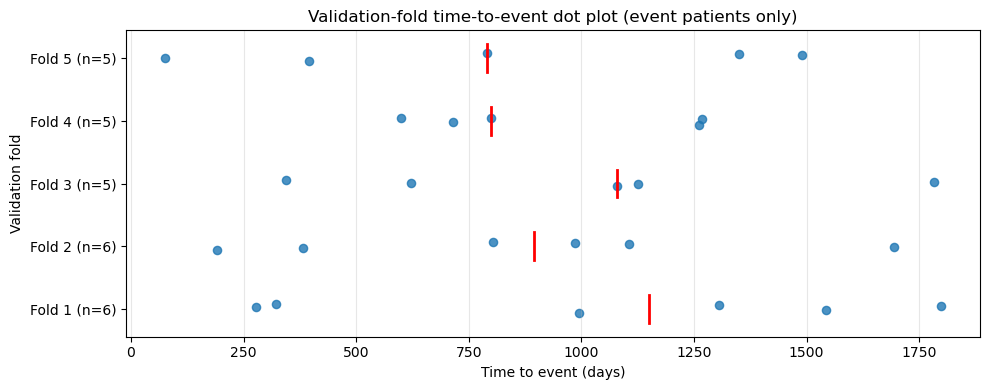

In [62]:
# Dot plot of time-to-event distribution per validation fold (events only)

fold_splits = manual_splits if 'manual_splits' in globals() else cv

plot_rows = []
for fold_id, (_, va_idx) in enumerate(fold_splits, start=1):
    va_times = time_col.iloc[va_idx]
    va_events = event_col.iloc[va_idx].astype(int)

    event_times = va_times[va_events == 1]
    for t in event_times:
        plot_rows.append({"fold": fold_id, "time": float(t)})

event_dot_df = pd.DataFrame(plot_rows)

if event_dot_df.empty:
    print("No events found in validation folds.")
else:
    fig, ax = plt.subplots(figsize=(10, 4))

    rng = np.random.default_rng(42)
    y_jitter = event_dot_df["fold"].values + rng.uniform(-0.08, 0.08, size=len(event_dot_df))
    ax.scatter(event_dot_df["time"], y_jitter, alpha=0.8, s=35)

    # Median event time per fold
    medians = event_dot_df.groupby("fold")["time"].median()
    for f, m in medians.items():
        ax.plot([m, m], [f - 0.22, f + 0.22], color="red", linewidth=2)

    counts = event_dot_df["fold"].value_counts().sort_index()
    ax.set_yticks(sorted(event_dot_df["fold"].unique()))
    ax.set_yticklabels([f"Fold {f} (n={counts.get(f, 0)})" for f in sorted(event_dot_df["fold"].unique())])

    ax.set_xlabel("Time to event (days)")
    ax.set_ylabel("Validation fold")
    ax.set_title("Validation-fold time-to-event dot plot (event patients only)")
    ax.grid(axis="x", alpha=0.3)

    plt.tight_layout()
    plt.show()

## Continuing

In [4]:
alpha_range = np.logspace(-4, -1, 10)
l1_ratio_range = [0.001, 0.01, 0.1, 0.5, 0.8, 1.0]

# alpha_range = [0.000464159]
# l1_ratio_range = [1.0]

n_controls = ["Full"]


metrics = ['c-index', 'int-brier-score', 'c-index-ipcw']

In [5]:
results_df, summary_df, best_params = subsampling_repeated_grid_search(
                                     subsampling, x_train, y_train, alpha_range, l1_ratio_range, 
                                     controls_per_case_range=n_controls, metrics=metrics, feature_columns=feature_columns,
                                     event_col='Recurrence', 
                                     time_col='Survival days',
                                     scale_data=True, scaler_type='minmax',
                                     continuous_features=continuous_features,
                                     use_sample_weights=False, weight_ratio=None,
                                     n_splits=4, n_repeats=1, base_random_state=42,
                                     verbose=True)

SUBSAMPLING REPEATED GRID SEARCH
Controls per case: ['Full']
L1 ratios: [0.001, 0.01, 0.1, 0.5, 0.8, 1.0]
Alphas: 10 values from 1.00e-04 to 1.00e-01
Total hyperparameter combinations: 60
Folds per repetition: 4
Repetitions: 1
Total evaluations: 240
Scaling: Yes (minmax)
Sample weights: No

[1/60] controls=Full (no subsampling), l1=0.001, alpha=1.00e-04 (elapsed: 0.0min, est. remaining: 0.0min)
[2/60] controls=Full (no subsampling), l1=0.001, alpha=2.15e-04 (elapsed: 0.0min, est. remaining: 1.0min)
[3/60] controls=Full (no subsampling), l1=0.001, alpha=4.64e-04 (elapsed: 0.1min, est. remaining: 1.0min)
[4/60] controls=Full (no subsampling), l1=0.001, alpha=1.00e-03 (elapsed: 0.1min, est. remaining: 0.9min)
[5/60] controls=Full (no subsampling), l1=0.001, alpha=2.15e-03 (elapsed: 0.1min, est. remaining: 0.9min)
[6/60] controls=Full (no subsampling), l1=0.001, alpha=4.64e-03 (elapsed: 0.1min, est. remaining: 0.9min)
[7/60] controls=Full (no subsampling), l1=0.001, alpha=1.00e-02 (elapsed

In [6]:
summary_df.to_csv('cox_new.csv', index=False)

In [23]:
results_df, summary_df, best_params = subsampling_bootstrap_optimism_grid_search(dataset, x_train, y_train, alpha_range, l1_ratio_range,
                                               n_controls, feature_columns,
                                               event_col='Regional LN recurrence',
                                               time_col='Survival days',
                                               scale_data=True, scaler_type='minmax',
                                               continuous_features=continuous_features,
                                               use_sample_weights=False, weight_ratio=None,
                                               n_bootstraps=100, base_random_state=42,
                                               verbose=True)

SUBSAMPLING STRATIFIED BOOTSTRAP OPTIMISM GRID SEARCH
Controls per case: ['Full']
L1 ratios: [1.0]
Alphas: 1 values from 4.64e-04 to 4.64e-04
Bootstrap runs per combination: 100
Total hyperparameter combinations: 1
Total model loops (B/C runs): 100
Scaling: Yes (minmax)
Sample weights: No

[1/1] controls=Full (no subsampling), l1=1.000, alpha=4.64e-04 (elapsed: 0.0min, est. remaining: 0.0min)


KeyboardInterrupt: 

In [34]:
cox_clean = clean_cox_data(summary_df)
cox_clean.to_csv('cox_new.csv', index=False)

  Checked 20 c-index fold columns and 20 c-index-ipcw fold columns
  Removed 3 rows with missing fold values (60 -> 57)


In [5]:
results_df, summary_df, best_params, bootstrap_df = subsampling_bootstrap_optimism_grid_search(dataset, x_train, y_train, alpha_range, l1_ratio_range,
                                               n_controls, feature_columns,
                                               event_col='Regional LN recurrence',
                                               time_col='Survival days',
                                               scale_data=True, scaler_type='minmax',
                                               continuous_features=continuous_features,
                                               use_sample_weights=False, weight_ratio=None,
                                               n_bootstraps=100, base_random_state=42,
                                               verbose=True, return_bootstrap_df=True
                                               )

SUBSAMPLING STRATIFIED BOOTSTRAP OPTIMISM GRID SEARCH
Controls per case: ['Full']
L1 ratios: [1.0]
Alphas: 1 values from 4.64e-04 to 4.64e-04
Bootstrap runs per combination: 100
Total hyperparameter combinations: 1
Total model loops (B/C runs): 100
Scaling: Yes (minmax)
Sample weights: No

[1/1] controls=Full (no subsampling), l1=1.000, alpha=4.64e-04 (elapsed: 0.0min, est. remaining: 0.0min)

BOOTSTRAP OPTIMISM GRID SEARCH COMPLETE
Total time: 0.8 minutes

Best parameters by optimism-corrected c-index:
  n_controls_per_case: Full (no subsampling)
  l1_ratio: 1.0000
  alpha: 4.6416e-04
  C_apparent: 0.9380
  Avg optimism: 0.0281
  C_final: 0.9099




In [6]:
bootstrap_df.to_csv('cox_bootstrap_results.csv', index=False)

In [6]:
bootstrap_df = pd.read_csv('cox_boot_full.csv')

In [7]:
c_boot_source = bootstrap_df.copy()

overall_ci = c_boot_source['c_final'].quantile([0.025, 0.975])
print('Overall c_final percentiles:')
print(f"2.5th percentile:  {overall_ci.loc[0.025]:.6f}")
print(f"97.5th percentile: {overall_ci.loc[0.975]:.6f}")

if {'n_controls', 'alpha', 'l1_ratio'}.issubset(c_boot_source.columns):
    per_combo_ci = (
        c_boot_source.groupby(['n_controls', 'alpha', 'l1_ratio'])['c_final']
        .quantile([0.025, 0.975])
        .unstack()
        .reset_index()
        .rename(columns={0.025: 'c_final_p2_5', 0.975: 'c_final_p97_5'})
    )
    print('\nPer-combination c_final percentiles:')
    print(per_combo_ci.to_string(index=False))
else:
    per_combo_ci = None


Overall c_final percentiles:
2.5th percentile:  0.862468
97.5th percentile: 0.953132

Per-combination c_final percentiles:
n_controls    alpha  l1_ratio  c_final_p2_5  c_final_p97_5
      Full 0.000464         1      0.862468       0.953132


In [ ]:
from math import sqrt
from scipy.stats import t as student_t

# 4-fold cross-validation on the training data
event_labels_train = y_train["event"].astype(int)

skf_4fold = StratifiedKFold(n_splits=4, shuffle=True, random_state=12)
cv_4fold_splits = list(skf_4fold.split(x_train, event_labels_train))

# ---- Fill these values later ----
mean_diff_input = 0.900927113
std_diff_input = 0.04858493
n_train_input = 1937
n_test_input = 645
n_evaluations_input = 20        # e.g., 5 folds * 4 repeats

ci_results = corrected_resampled_t_confidence_interval(
    mean_diff=mean_diff_input,
    std_diff=std_diff_input,
    n_train=n_train_input,
    n_test=n_test_input,
    n_evaluations=n_evaluations_input,
    alpha=0.05,
 )

print(f"Corrected SE: {ci_results['standard_error_corrected']:.6f}")
print(f"95% CI: [{ci_results['ci_low']:.6f}, {ci_results['ci_high']:.6f}]")

Corrected SE: 0.030067
95% CI: [0.837995, 0.963859]


In [ ]:
binary_variables = ['Adjuvant therapy using biological drugs', 'Trastuzumab or other drugs', 'Radiotherapy (RT) performed', 
 'Radiotherapy on chest wall', 'Radiotherapy on supraclavicular area', 'Radiotherapy on internal mammary chain', 
 'Endocrine therapy performed', 'State (if hormone therapy prescribed)', 'Treatment in association with chemotherapy', 
 'Chemotherapy performed', 'Adjuvant chemotherapy', 'Type of invasion at CB', 'Progesterone receptor status at CB',  'Side location of the lesion', 
 'Source of referral', ]
 
continuous_variables = ['Conventional RT fraction', 'Total administered dose', 'Boost dose administered', 'Age', 'Ki67 positive cells (%) at CB',
                         'Grade at CB']

ohe = {
    'N (Regional nodes affected)': ['N (Regional nodes affected)_1.0', 'N (Regional nodes affected)_23'],
    'Oestrogen receptor status at CB': ['Oestrogen receptor status at CB_0.0', 'Oestrogen receptor status at CB_1.0'],
    'Her2 overexpression (with immunohystochemistry) at CB': ['Her2 overexpression (with immunohystochemistry) at CB_1.0', 'Her2 overexpression (with immunohystochemistry) at CB_2.0', 'Her2 overexpression (with immunohystochemistry) at CB_3.0'],
    'Number identifying the lesion in the patient': ['Number identifying the lesion in the patient_2', 'Number identifying the lesion in the patient_34'],
    'Classification with respect to other lesions': ['Classification with respect to other lesions_2.0', 'Classification with respect to other lesions_3.0'],
    'Isotype at CB': ['Isotype at CB_1.0', 'Isotype at CB_2.0', 'Isotype at CB_3.0', 'Isotype at CB_4.0'],
    'Disease extent': ['Disease extent_1.0', 'Disease extent_2.0']
}

In [4]:
# Define time points for calibration analysis (1, 2, 3, 4, 5 years)
time_points = [365, 730, 1095, 1460, 1825]  # in days

# Use the best model parameters found earlier
best_params_for_calibration = {
    'alphas': [0.000464159],
    'l1_ratio': 1.0,
    'fit_baseline_model': True
    }

n_controls=["Full"]

# predictions_df = pd.read_csv("cox_calibration_predictions.csv")

In [ ]:
# Collect predictions using repeated CV (same methodology as training)
predictions_df, threshold_metrics_df = collect_cv_predictions_for_calibration(
    model_class=CoxnetSurvivalAnalysis,
    X=x_train,
    y=y_train,
    model_params=best_params_for_calibration,
    time_points=time_points,
    scale_data=True,
    scaler_type='minmax', 
    continuous_features=continuous_features,
    random_state=None,
    n_jobs=-1,
    n_controls_per_case=None,  
    dataset=subsampling,
    feature_columns=feature_columns,
    event_col='Regional LN recurrence',
    time_col='Survival days',
    n_splits=4,
    n_repeats=1, 
    base_random_state=42,
    recalibrate=False,
    calculate_threshold=True,
    verbose=True
)

# Save predictions for later analysis
predictions_df.to_csv('cox_calibration_predictions.csv', index=False)
threshold_metrics_df.to_csv('cox_threshold_metrics.csv', index=False)
print(f"\nPredictions saved to 'cox_calibration_predictions.csv'")
print(f"Threshold metrics saved to 'cox_threshold_metrics.csv'")

Time points: [365, 730, 1095, 1460, 1825]
CV: 1 repeats x 4 folds = 4 models
Threshold mode: ON (optimize per-fold, per-timepoint thresholds)

Repeat 1/1
  Fold 1/4... Creating model with params: {'alphas': [0.000464159], 'l1_ratio': 1.0, 'fit_baseline_model': True}
Done
  Fold 2/4... Creating model with params: {'alphas': [0.000464159], 'l1_ratio': 1.0, 'fit_baseline_model': True}
Done
  Fold 3/4... Creating model with params: {'alphas': [0.000464159], 'l1_ratio': 1.0, 'fit_baseline_model': True}
Done
  Fold 4/4... Creating model with params: {'alphas': [0.000464159], 'l1_ratio': 1.0, 'fit_baseline_model': True}
Done

Total predictions collected: 2582
Unique samples: 2582
Total threshold-metric rows: 20

Predictions saved to 'cox_calibration_predictions.csv'
Threshold metrics saved to 'cox_threshold_metrics.csv'


In [ ]:
# Column-wise statistics for all numeric columns
numeric_cols = threshold_metrics_df.select_dtypes(include=[np.number]).columns

col_stats = threshold_metrics_df[numeric_cols].describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
).T

col_stats["missing"] = threshold_metrics_df[numeric_cols].isna().sum()
col_stats["missing_pct"] = (col_stats["missing"] / len(threshold_metrics_df) * 100).round(2)
col_stats["unique"] = threshold_metrics_df[numeric_cols].nunique()

print("Column-wise statistics (overall):")
print(col_stats.round(4).to_string())

# Optional: statistics by time point for key model metrics
metric_cols = ["sensitivity", "specificity", "PPV", "NPV", "accuracy", "F1_score", "threshold"]

stats_by_time = (
    threshold_metrics_df.groupby("time_days")[metric_cols]
    .describe(percentiles=[0.25, 0.5, 0.75])
    .round(4)
)

print("\nColumn-wise statistics grouped by time_days:")
print(stats_by_time.to_string())

Column-wise statistics (overall):
                 count       mean       std        min         1%         5%        25%        50%        75%        95%        99%        max  missing  missing_pct  unique
repeat_idx        20.0     0.0000    0.0000     0.0000     0.0000     0.0000     0.0000     0.0000     0.0000     0.0000     0.0000     0.0000        0          0.0       1
fold_idx          20.0     1.5000    1.1471     0.0000     0.0000     0.0000     0.7500     1.5000     2.2500     3.0000     3.0000     3.0000        0          0.0       4
time_days         20.0  1095.0000  529.5977   365.0000   365.0000   365.0000   730.0000  1095.0000  1460.0000  1825.0000  1825.0000  1825.0000        0          0.0       5
time_years        20.0     3.0000    1.4510     1.0000     1.0000     1.0000     2.0000     3.0000     4.0000     5.0000     5.0000     5.0000        0          0.0       5
threshold         20.0     0.0068    0.0042     0.0018     0.0019     0.0022     0.0039     0.0055   

Jittered risk score plot saved to cox_actually_min_risk_score_distribution.png

Time point 365 days:
  Events: 5, No events: 2427
  Mean survival prob (event): 0.991
  Mean survival prob (no event): 0.998
  Cohen's d: 1.21

Time point 730 days:
  Events: 8, No events: 1891
  Mean survival prob (event): 0.978
  Mean survival prob (no event): 0.997
  Cohen's d: 1.56

Time point 1095 days:
  Events: 13, No events: 1621
  Mean survival prob (event): 0.957
  Mean survival prob (no event): 0.994
  Cohen's d: 1.46

Time point 1460 days:
  Events: 18, No events: 1148
  Mean survival prob (event): 0.945
  Mean survival prob (no event): 0.990
  Cohen's d: 1.10

Time point 1825 days:
  Events: 22, No events: 910
  Mean survival prob (event): 0.935
  Mean survival prob (no event): 0.985
  Cohen's d: 0.91


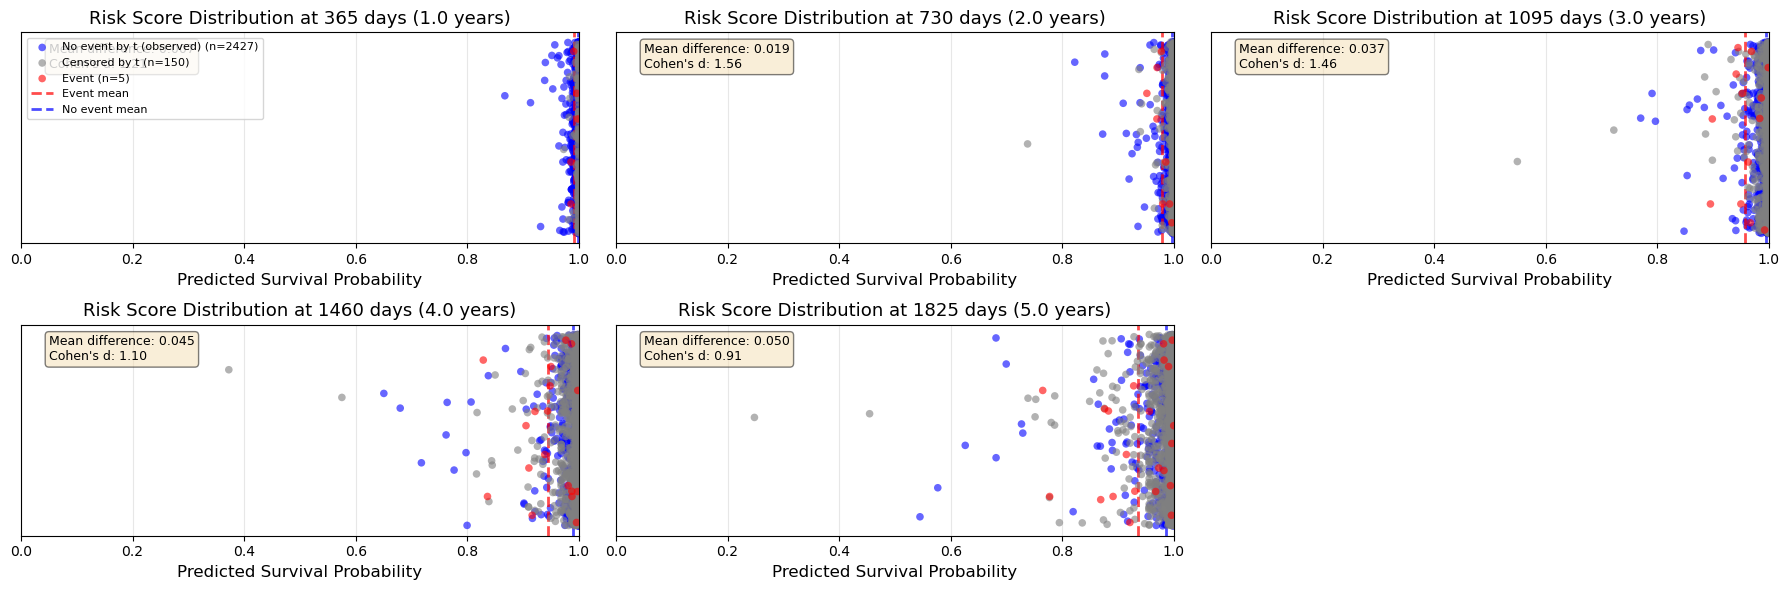

In [ ]:
# Basic usage
fig, axes, stats = plot_jittered_risk_scores(
    predictions_df=predictions_df,
    time_points=time_points,
    figsize=(18, 6),
    save_path='cox_actually_min_risk_score_distribution.png'
)  

# Check separation statistics
for t, stat in stats.items():
    print(f"\nTime point {t} days:")
    print(f"  Events: {stat['n_events']}, No events: {stat['n_no_events']}")
    print(f"  Mean survival prob (event): {stat['event_mean']:.3f}")
    print(f"  Mean survival prob (no event): {stat['no_event_mean']:.3f}")
    print(f"  Cohen's d: {stat['cohens_d']:.2f}")

In [ ]:
# Calculate Brier Score at each time point
brier_scores = {}

for t in time_points:
    col_name = f'pred_surv_{int(t)}d'
    
    # Get predictions and actual outcomes
    df_temp = predictions_df[['sample_idx', 'event', 'time', col_name]].dropna()
    
    # Calculate observed outcome at this time point
    # 1 if survived past time point, 0 if had event before/at time point
    observed = ((df_temp['time'] > t) | 
                ((df_temp['time'] <= t) & (df_temp['event'] == 0))).astype(int)
    
    predicted = df_temp[col_name].values
    
    # Brier Score: mean squared error between predicted and observed
    brier = np.mean((predicted - observed) ** 2)
    
    brier_scores[t] = brier
    print(f"Time point {t} days ({t/365:.1f} years): Brier Score = {brier:.4f}")

# Store in a DataFrame for easy viewing
brier_scores_df = pd.DataFrame([
    {'time_point_days': t, 'time_point_years': t/365, 'brier_score': score}
    for t, score in brier_scores.items()
])

print("\nBrier Scores Summary:")
print(brier_scores_df.to_string(index=False))

Time point 365 days (1.0 years): Brier Score = 0.0019
Time point 730 days (2.0 years): Brier Score = 0.0031
Time point 1095 days (3.0 years): Brier Score = 0.0050
Time point 1460 days (4.0 years): Brier Score = 0.0070
Time point 1825 days (5.0 years): Brier Score = 0.0088

Brier Scores Summary:
 time_point_days  time_point_years  brier_score
             365               1.0     0.001936
             730               2.0     0.003074
            1095               3.0     0.004954
            1460               4.0     0.007010
            1825               5.0     0.008835


Calibration plot saved to cox_actually_calibration_curves.png


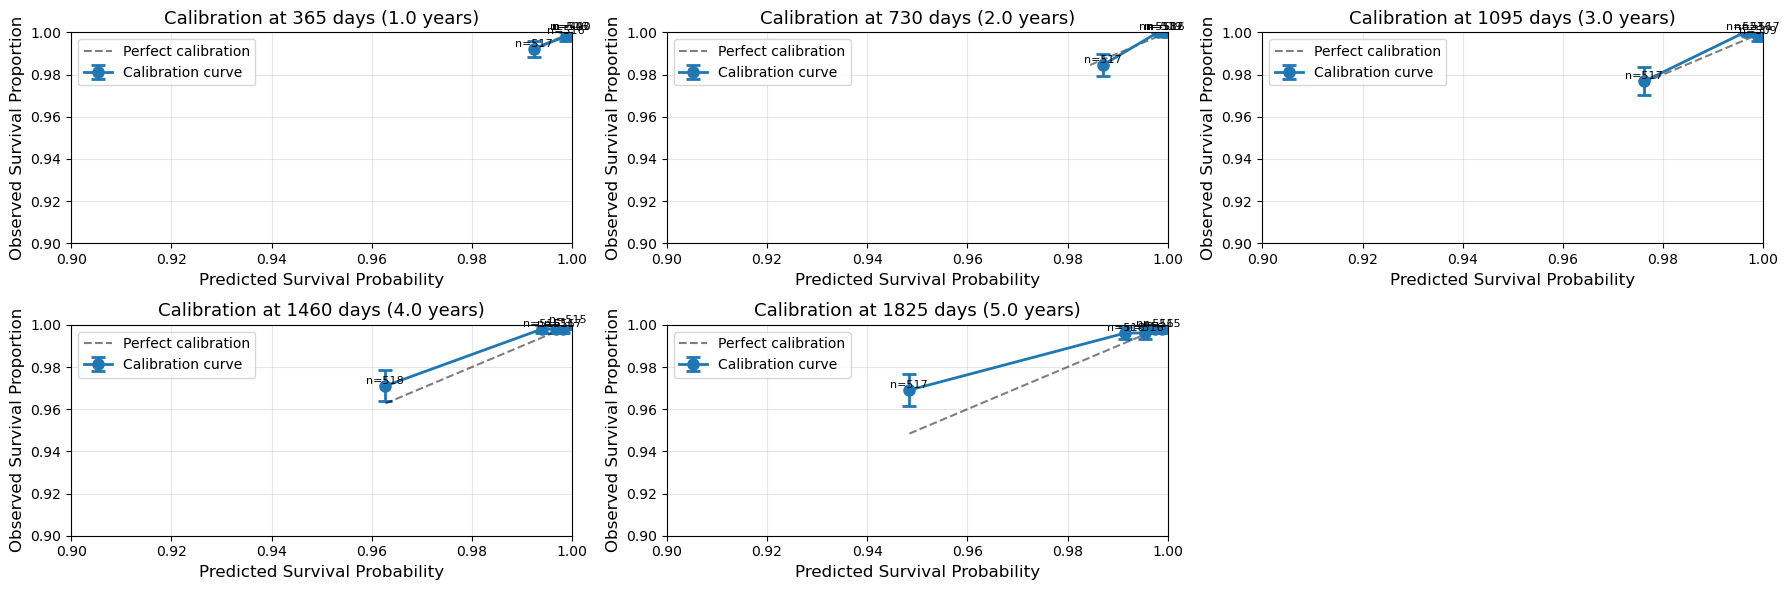

In [ ]:
# Generate calibration curves for all time points
fig, axes, calibration_results = plot_calibration_curves(
    predictions_df=predictions_df,
    time_points=time_points,
    n_bins=5,
    strategy='quantile',  # Equal-sized bins based on prediction quantiles
    figsize=(18, 6),
    save_path='cox_actually_calibration_curves.png',
    xlim=(0.9, 1),
    ylim=(0.9, 1),
    error_bar_type='se'
)

plt.show()

  Processing fold 1/12...
  Processing fold 2/12...
  Processing fold 3/12...
  Processing fold 4/12...
  Processing fold 5/12...
  Processing fold 6/12...
  Processing fold 7/12...
  Processing fold 8/12...
  Processing fold 9/12...
  Processing fold 10/12...
  Processing fold 11/12...
  Processing fold 12/12...

  Collected survival curves for 2582 patients


(<Figure size 1500x1000 with 1 Axes>,
 <Axes: title={'center': 'Individual Patient Survival Curves (CV Predictions)'}, xlabel='Time (days)', ylabel='Predicted Survival Probability'>,
     patient_idx  event    time event_status  n_predictions
 0           211   True   790.0        Event              1
 1           539   True  1799.0        Event              1
 2           662   True  1784.0        Event              1
 3           700   True  1543.0        Event              1
 4           703   True  1106.0        Event              1
 5           751   True  1306.0        Event              1
 6           867   True  1262.0        Event              1
 7           913   True   345.0        Event              1
 8           950   True  1351.0        Event              1
 9           973   True   278.0        Event              1
 10         1024   True   799.0        Event              1
 11         1054   True   986.0        Event              1
 12         1132   True   192.0      

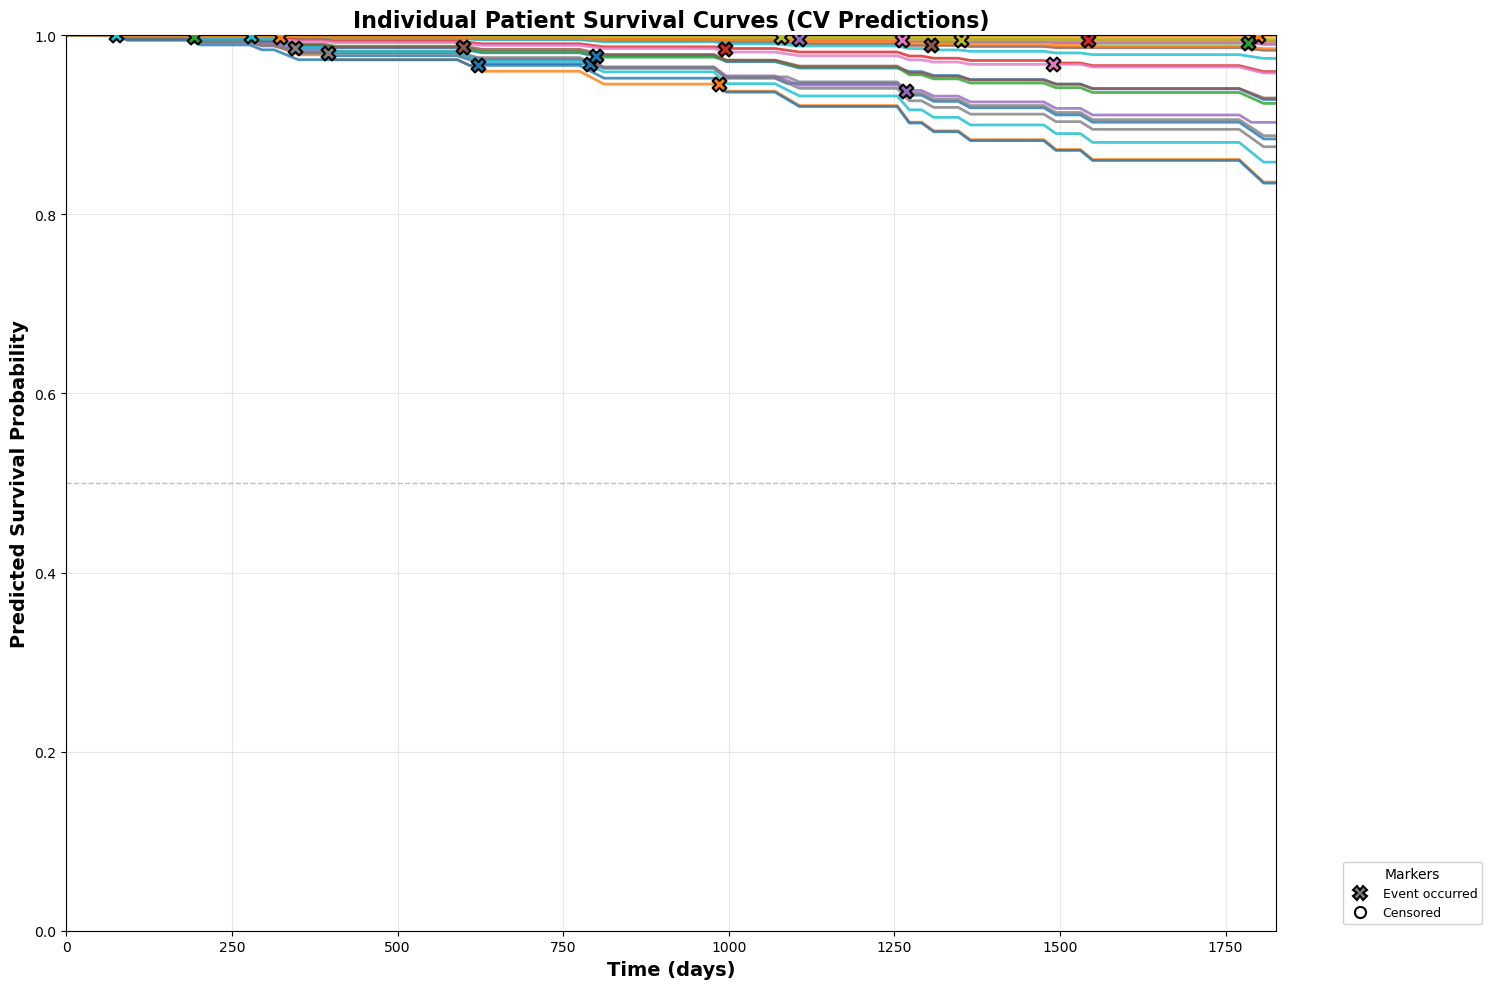

In [ ]:
plot_individual_survival_curves(model_class=CoxnetSurvivalAnalysis, X=x_train, y=y_train, model_params=best_params_for_calibration,
                                    patient_indices=None, 
                                    n_patients=24, select_events_only=True,
                                    scale_data=True, scaler_type='minmax',
                                    continuous_features=continuous_features,
                                    n_controls_per_case=None, dataset=None,
                                    feature_columns=None,
                                    event_col='Regional LN recurrence',
                                    time_col='Survival days',
                                    n_splits=12, n_repeats=1, random_state=42,
                                    time_range=None, n_time_points=100,
                                    figsize=(15, 10), save_path=None,
                                    show_event_markers=True, show_censoring_markers=True,
                                    event_marker_size=100, censoring_marker_size=80,
                                    colormap='tab10', alpha=0.8,
                                    show_legend=True, legend_outside=True,
                                    show_confidence_interval=False, ci_alpha=0.2,
                                    compute_weights=False,
                                    verbose=True)

In [ ]:
# Patients with most wrong classifications across time points (recurrence patients only)
# Wrong classification = predicted event label differs from true event-by-time label.

# Choose which threshold set to use (prefer high-specificity if available)
if 'threshold_high_specificity' in globals() and isinstance(threshold_high_specificity, dict):
    threshold_dict = threshold_high_specificity
    threshold_name = 'high_specificity_strategy'
elif 'threshold_high_sensitivity' in globals() and isinstance(threshold_high_sensitivity, dict):
    threshold_dict = threshold_high_sensitivity
    threshold_name = 'high_sensitivity_strategy'
else:
    threshold_dict = {t: 0.5 for t in time_points}
    threshold_name = 'default_0.5'

# In this dataset, sample_idx is the patient identifier (PERSON_ID)
if 'sample_idx' in predictions_df.columns:
    patient_id_col = 'sample_idx'
elif 'PERSON_ID' in predictions_df.columns:
    patient_id_col = 'PERSON_ID'
else:
    raise ValueError("predictions_df needs 'sample_idx' (or 'PERSON_ID') for patient-level error counts.")

patient_eval_rows = []
for t in time_points:
    col_name = f'pred_surv_{int(t)}d'
    if col_name not in predictions_df.columns:
        continue

    df_t = predictions_df[[patient_id_col, col_name, 'event', 'time']].dropna().copy()

    # Aggregate repeated CV predictions to one probability per patient and horizon
    df_t = (
        df_t.groupby(patient_id_col, as_index=False)
        .agg({col_name: 'mean', 'event': 'first', 'time': 'first'})
    )

    # Keep recurrence patients only
    df_t = df_t[df_t['event'] == 1].copy()

    # True class at horizon t: recurrence occurred by t
    df_t['true_event_by_t'] = (df_t['time'] <= t).astype(int)

    # Predicted class from risk score and selected threshold
    thr = float(threshold_dict.get(t, 0.5))
    df_t['risk_score'] = 1 - df_t[col_name]
    df_t['pred_event_by_t'] = (df_t['risk_score'] >= thr).astype(int)
    df_t['wrong'] = (df_t['pred_event_by_t'] != df_t['true_event_by_t']).astype(int)

    df_t['time_days'] = t
    df_t['threshold_used'] = thr
    patient_eval_rows.append(df_t[[patient_id_col, 'time_days', 'event', 'true_event_by_t', 'pred_event_by_t', 'wrong', 'threshold_used']])

if len(patient_eval_rows) == 0:
    raise ValueError('No valid prediction columns found for the selected time_points.')

patient_eval_df = pd.concat(patient_eval_rows, ignore_index=True).rename(columns={patient_id_col: 'PERSON_ID'})

# Count wrong classifications per recurrence patient
patient_error_summary = (
    patient_eval_df.groupby('PERSON_ID', as_index=False)
    .agg(
        n_wrong=('wrong', 'sum'),
        n_evaluations=('wrong', 'count')
    )
)
patient_error_summary['wrong_rate'] = patient_error_summary['n_wrong'] / patient_error_summary['n_evaluations']

# Rank patients: most wrong first
patient_error_summary = patient_error_summary.sort_values(
    ['n_wrong', 'wrong_rate', 'PERSON_ID'],
    ascending=[False, False, True]
).reset_index(drop=True)

n_recurrence_patients = patient_error_summary['PERSON_ID'].nunique()
print(f"Threshold set used: {threshold_name}")
print(f"Recurrence patients evaluated: {n_recurrence_patients}")
print('Top recurrence patients with most wrong classifications:')
print(patient_error_summary.head(20).to_string(index=False))

# Optional: inspect all horizon-level errors for the top recurrence patients
top_patient_ids = patient_error_summary.head(10)['PERSON_ID'].tolist()
patient_error_details_top = patient_eval_df[patient_eval_df['PERSON_ID'].isin(top_patient_ids)].copy()
patient_error_details_top = patient_error_details_top.sort_values(['PERSON_ID', 'time_days'])

print('\nDetailed errors for top 10 recurrence patients:')
print(patient_error_details_top.to_string(index=False))

Threshold set used: default_0.5
Recurrence patients evaluated: 22
Top recurrence patients with most wrong classifications:
 PERSON_ID  n_wrong  n_evaluations  wrong_rate
       913        5              5         1.0
       973        5              5         1.0
      1132        5              5         1.0
      1986        5              5         1.0
      2164        5              5         1.0
      1574        4              5         0.8
      1653        4              5         0.8
      2089        4              5         0.8
       211        3              5         0.6
      1024        3              5         0.6
      1054        3              5         0.6
      1191        3              5         0.6
      1898        3              5         0.6
       703        2              5         0.4
       751        2              5         0.4
       867        2              5         0.4
       950        2              5         0.4
      1566        2            